In [ ]:
!pip install lightkurve scikit-learn pandas numpy matplotlib

In [ ]:
import lightkurve as lk
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import numpy as np

### First, I'll be downloading data for the star "Kepler-10" using Lightkurve.

In [ ]:
search_result = lk.search_lightcurve('Kepler-10', author='Kepler', exptime='long').download_all()
print(search_result)

LightCurveCollection of 15 objects:
    0: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=0 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    1: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=1 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    2: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=2 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    3: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=3 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    4: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=4 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    5: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=5 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    6: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=6 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    7: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=7 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    8: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=9 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    9: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=10 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    10: <Kepl

### Next, I'll use ".stitch()" to merge all the seperate observations into one lightcurve.

In [ ]:
stitched_lc = search_result.stitch()

### After stitching, I'm going to use:
 ##### 1. ".normalize()" to remove instrumetal differences
 ##### 2. ".flatten()" to manage stellar variability and thermal changes
 ##### 3. ".remove_outliers()" to remove anomalous data

In [ ]:
lc = stitched_lc.normalize().flatten().remove_outliers()

In [ ]:
custom_periods = np.linspace(0.5, 20, 10000)

#### Next, I'm creating a periodogram with the Box Least Squares method to find repeating dips caused by transiting exoplanets.

In [ ]:
periodogram = lc.to_periodogram(method='bls', period=custom_periods)

`period` contains 8432814 points.Periodogram is likely to be large, and slow to evaluate. Consider setting `frequency_factor` to a higher value.


<Axes: xlabel='Period [$\\mathrm{d}$]', ylabel='BLS Power'>

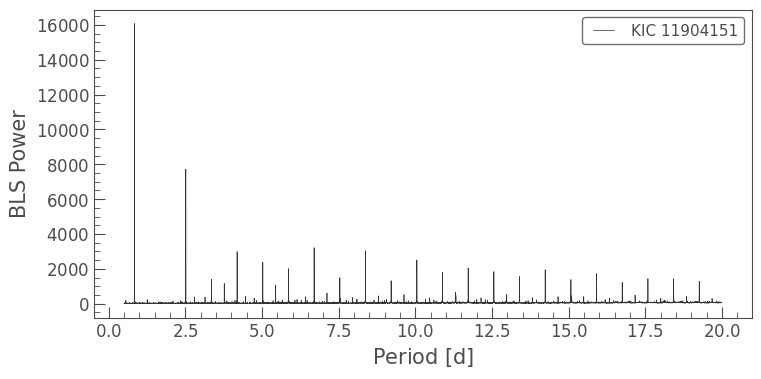

In [ ]:
periodogram.plot()

#### Next, I'll find the most likely planet period and generate a graph to check if my data is correct.

In [ ]:
best_period = periodogram.period_at_max_power
print("The most likely planet period is: " + str(best_period) + "ays")

The most likely planet period is: 0.8373837383738373 days


<Axes: xlabel='Phase [JD]', ylabel='Normalized Flux'>

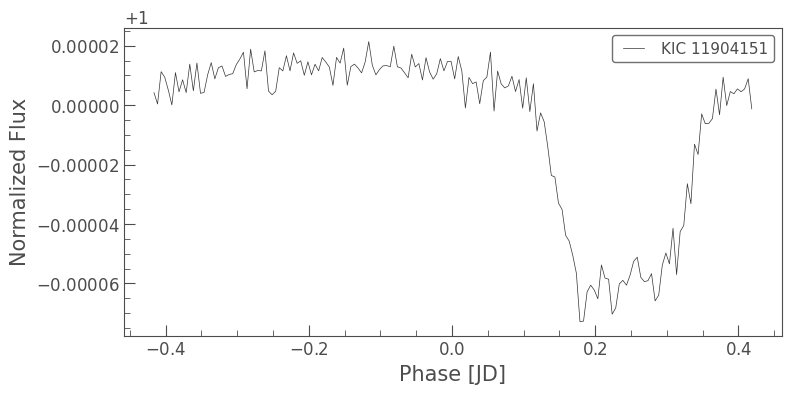

In [ ]:
folded_lc = lc.fold(best_period).bin(time_bin_size=0.005)
folded_lc.plot()